# Business Case

Axis Bank is trying to categorize its customers so that it can advertise its Credit Card service to the right people and get more customers to sign up.

You are a data scientist there. Your job is to classify the customers based on their expenditure, family size, age and marital status.

Let's load the data.

**Dataset link:** https://drive.google.com/uc?id=1wKmz9mcng9dBsILIhhdwkoWg5_BhVhe6

In [ ]:
!gdown 1wKmz9mcng9dBsILIhhdwkoWg5_BhVhe6

Downloading...
From: https://drive.google.com/uc?id=1wKmz9mcng9dBsILIhhdwkoWg5_BhVhe6
To: /content/customer_train.csv
100% 425k/425k [00:00<00:00, 111MB/s]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('customer_train.csv')

df.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


In [ ]:
df.drop(columns=['Var_1', 'ID'], inplace = True)

In [ ]:
df.head()

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Segmentation
0,Male,No,22,No,Healthcare,1.0,Low,4.0,D
1,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,A
2,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,B
3,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,B
4,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,A


In [ ]:
df.isnull().sum()

,0
Gender,0
Ever_Married,140
Age,0
Graduated,78
Profession,124
Work_Experience,829
Spending_Score,0
Family_Size,335
Segmentation,0


In [ ]:
df.shape

(8068, 9)

In [ ]:
df.dropna(inplace=True)

In [ ]:
df.shape

(6718, 9)

In [ ]:
df.isnull().sum()

,0
Gender,0
Ever_Married,0
Age,0
Graduated,0
Profession,0
Work_Experience,0
Spending_Score,0
Family_Size,0
Segmentation,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6718 entries, 0 to 8067
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Gender           6718 non-null   object 
 1   Ever_Married     6718 non-null   object 
 2   Age              6718 non-null   int64  
 3   Graduated        6718 non-null   object 
 4   Profession       6718 non-null   object 
 5   Work_Experience  6718 non-null   float64
 6   Spending_Score   6718 non-null   object 
 7   Family_Size      6718 non-null   float64
 8   Segmentation     6718 non-null   object 
dtypes: float64(2), int64(1), object(6)
memory usage: 524.8+ KB


In [ ]:
df.Segmentation.value_counts()

,count
Segmentation,
D,1772
C,1735
A,1628
B,1583


In [ ]:
classes = sorted(df['Segmentation'].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

y = df['Segmentation'].map(class_to_idx)
X = df.drop(columns=['Segmentation'])

print(classes, class_to_idx)

['A', 'B', 'C', 'D'] {'A': 0, 'B': 1, 'C': 2, 'D': 3}


In [ ]:
y.unique()

array([3, 1, 2, 0])

In [ ]:
X.head()

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size
0,Male,No,22,No,Healthcare,1.0,Low,4.0
2,Female,Yes,67,Yes,Engineer,1.0,Low,1.0
3,Male,Yes,67,Yes,Lawyer,0.0,High,2.0
5,Male,Yes,56,No,Artist,0.0,Average,2.0
6,Male,No,32,Yes,Healthcare,1.0,Low,3.0


In [ ]:
X = pd.get_dummies(X, columns=['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score'], dtype=float)

X.head()

,Age,Work_Experience,Family_Size,Gender_Female,Gender_Male,Ever_Married_No,Ever_Married_Yes,Graduated_No,Graduated_Yes,Profession_Artist,...,Profession_Engineer,Profession_Entertainment,Profession_Executive,Profession_Healthcare,Profession_Homemaker,Profession_Lawyer,Profession_Marketing,Spending_Score_Average,Spending_Score_High,Spending_Score_Low
0,22,1.0,4.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,67,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,67,0.0,2.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
5,56,0.0,2.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
6,32,1.0,3.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=42)

print('Train : ', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test  : ', X_test.shape, y_test.shape)

Train :  (5441, 21) (5441,)
Validation: (605, 21) (605,)
Test  :  (672, 21) (672,)


In [ ]:
from sklearn.preprocessing import StandardScaler

X_val_df = X_val.copy()      # keep an unscaled copy of the validation rows, we will need it for error analysis later

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [ ]:
import torch
import torch.nn as nn
# import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

np.random.seed(42)
_ = torch.manual_seed(42)

In [ ]:
def create_baseline(in_features, n_classes=4):
    model = nn.Sequential(
        nn.Linear(in_features, 64), nn.ReLU(),
        nn.Linear(64, 32), nn.ReLU(),
        nn.Linear(32, 16), nn.ReLU(),
        nn.Linear(16, 8), nn.ReLU(),
        nn.Linear(8, n_classes),          # raw logits: no softmax here, nn.CrossEntropyLoss adds it
    )
    # Glorot (Xavier) initialization with zero biases
    for layer in model:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    return model

In [ ]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t   = torch.tensor(X_val,   dtype=torch.float32)
X_test_t  = torch.tensor(X_test,  dtype=torch.float32)

y_train_t = torch.tensor(y_train.values, dtype=torch.long)
y_val_t   = torch.tensor(y_val.values,   dtype=torch.long)
y_test_t  = torch.tensor(y_test.values,  dtype=torch.long)

model = create_baseline(X_train_t.shape[1])
print(model)

Sequential(
  (0): Linear(in_features=21, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=8, bias=True)
  (7): ReLU()
  (8): Linear(in_features=8, out_features=4, bias=True)
)


In [ ]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

loss_fn = nn.CrossEntropyLoss()

def predict(model, X):
    # Returns the raw scores and the predicted class, with gradient tracking switched off
    model.eval()
    with torch.no_grad():
        logits = model(X)
    return logits, logits.argmax(dim=1)

In [ ]:
def train_model(model, lr=1e-3, epochs=10, batch_size=128):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
    history = {k: [] for k in ["loss", "precision", "recall", "f1",
                               "val_loss", "val_precision", "val_recall", "val_f1"]}
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()              # 1. clear the old gradients
            loss = loss_fn(model(xb), yb)      # 2. forward pass and loss
            loss.backward()                    # 3. backpropagation
            optimizer.step()                   # 4. update the weights

        # metrics on the full train and validation sets at the end of every epoch
        for prefix, X_, y_ in [("", X_train_t, y_train_t), ("val_", X_val_t, y_val_t)]:
            logits, pred = predict(model, X_)
            y_np, p_np = y_.numpy(), pred.numpy()
            history[prefix + "loss"].append(loss_fn(logits, y_).item())
            history[prefix + "precision"].append(precision_score(y_np, p_np, average="macro", zero_division=0))
            history[prefix + "recall"].append(recall_score(y_np, p_np, average="macro", zero_division=0))
            history[prefix + "f1"].append(f1_score(y_np, p_np, average="macro", zero_division=0))
    return history

In [ ]:
def plot_history(history, metric, title=None):
    epochs = range(1, len(history[metric]) + 1)
    plt.plot(epochs, history[metric], label="train")
    plt.plot(epochs, history["val_" + metric], label="validation")
    plt.xlabel("epoch")
    plt.ylabel(metric)
    plt.legend()
    plt.title(title or f"{metric} vs epochs")
    plt.show()

In [ ]:
torch.manual_seed(42)

model = create_baseline(X_train_t.shape[1])

history = train_model(model, lr = 1e-3, epochs=10, batch_size=128)

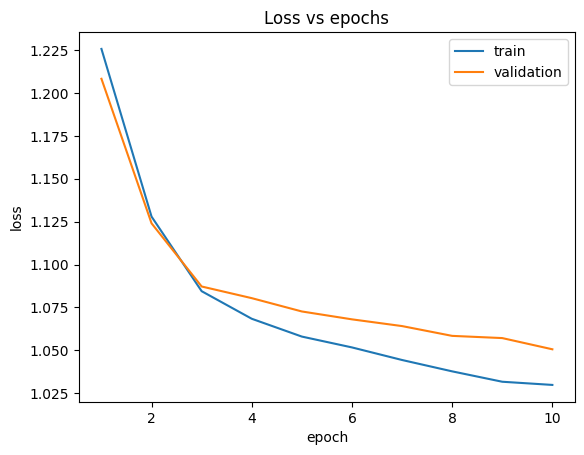

In [ ]:
plot_history(history, "loss", title="Loss vs epochs")

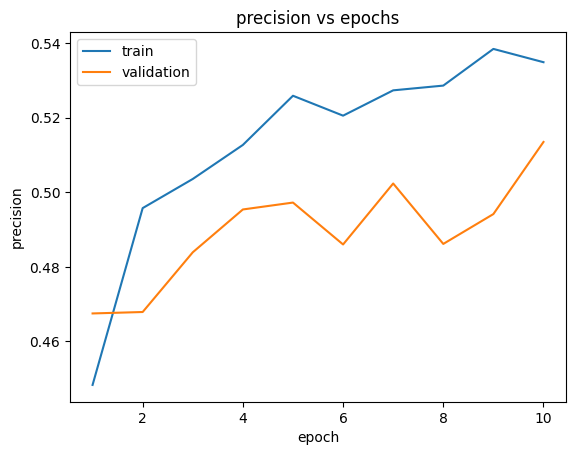

In [ ]:
plot_history(history, "precision", title="precision vs epochs")

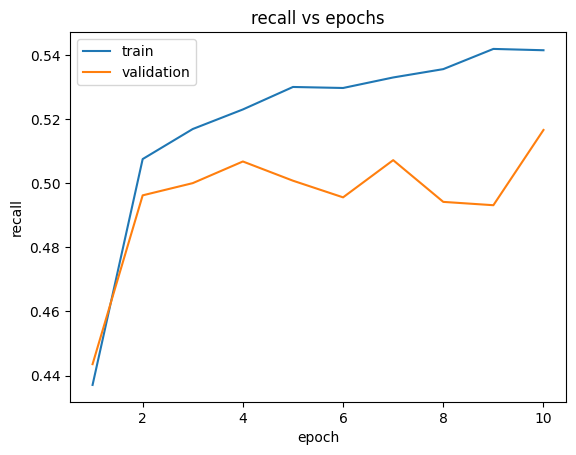

In [ ]:
plot_history(history, "recall", title="recall vs epochs")

In [ ]:
lr_results = {}
for lr in [1e-5, 1e-3, 1e-2, 1e-1, 1.0]:
    torch.manual_seed(42)                                   # same starting weights for every run
    lr_results[lr] = train_model(create_baseline(X_train_t.shape[1]), lr=lr, epochs=10)

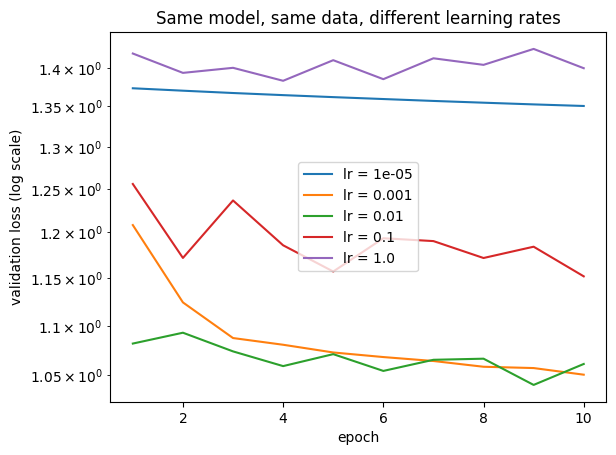

,final validation loss
0.00001,1.3506
0.00100,1.0506
0.01000,1.0612
0.10000,1.1518
1.00000,1.3991


In [ ]:
for lr, h in lr_results.items():
    plt.plot(range(1, 11), h["val_loss"], label=f"lr = {lr}")
plt.xlabel("epoch")
plt.ylabel("validation loss (log scale)")
plt.yscale("log")                                           # a log scale keeps a diverging run from hiding the others
plt.legend()
plt.title("Same model, same data, different learning rates")
plt.show()

pd.Series({lr: round(h["val_loss"][-1], 4) for lr, h in lr_results.items()}, name="final validation loss")

In [ ]:
# You can afford 25 training runs to tune two hyperparameters: the learning rate,
# which matters a lot, and the batch size, which matters little. Why is random search usually better than a 5 × 5 grid here?